# Importing FOF-CT chromatin-tracing data

The [4DN FISH Omics Format — Chromatin Tracing](https://fish-omics-format.readthedocs.io/)
(FOF-CT) is the community format for multiplexed DNA-FISH / chromatin-tracing results: a
*core table* (one row per DNA spot, with `##` / `#` metadata headers) plus optional companion
tables (cells, RNA spots, cell outlines).  In this tutorial you read a real FOF-CT dataset with
`ChromData.from_fofct` (package `chromdata`), attach its cell and RNA-spot tables, look at the
header metadata and the cell positions, write everything back with `ChromData.to_fofct` and
check the round trip, and finally stream the import straight into a `.chromdata.zarr` store
(`from_fofct(..., out=)`).

**Data**: Takei et al. 2021, *Nature* 590:344 ("Integrated spatial genomics reveals global
architecture of single nuclei") — DNA seqFISH+ of E14 mouse ES cells, 4DN files
`4DNFIHF3JCBY` (core table: 20 chromosomes × 60 loci at 25 kb, 201 cells), `4DNFIFINA2U9`
(cell table) and `4DNFIJ52NVDV` (nascent-RNA spots); `ds.fetch("takei")` and
`ds.fetch("takei_tables")` download them once from the 4DN data portal.  **Runtime**: under
a minute.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from chromdata import ChromData
import uchrom.datasets as ds

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

CORE = ds.fetch("takei")                       # core table (4DN, 22 MB; downloaded once)
T = ds.fetch("takei_tables")                   # its cell table and nascent-RNA spot table (4DN)
CELLS, RNA = T / "4DNFIFINA2U9.csv", T / "4DNFIJ52NVDV.csv"
for p in (CORE, CELLS, RNA):
    print(f"{p.relative_to(ds.data_dir())}  ({p.stat().st_size / 1e6:.2f} MB)")

4DNFIHF3JCBY.csv  (21.86 MB)
4DNFIFINA2U9.csv  (0.06 MB)
4DNFIJ52NVDV.csv  (0.22 MB)


## 1. What a FOF-CT core table looks like

Lines starting with `##` are the required header fields (format version, table namespace,
genome assembly, unit of X/Y/Z); `#` lines are optional free-text fields; `##columns=(...)`
names the columns of the data rows that follow.

In [2]:
with open(CORE) as fh:
    for line in fh.readlines()[:18]:
        print(line.rstrip().rstrip(",")[:110])

##FOF-CT_version=v0.1
##Table_namespace=4dn_FOF-CT_core
##genome_assembly=GRCm38/mm10
##XYZ_unit=micron
#Software_Title: dna-seqfish-plus
#Software_Type: preprocess+process+decode
"#Software_Authors: Takei, Yodai; Pierson, Nico; Shah, Sheel; White, Jonathan; Cai, Long"
#Software_Description: dna-seqfish-plus software was developed for processing the images and barcode calling f
#Software_Repository: https://github.com/CaiGroup/dna-seqfish-plus
#Software_PreferredCitationID: https://www.nature.com/articles/s41586-020-03126-2
#lab_name: Cai
#experimenter_name: Yodai Takei
#experimenter_contact: ytakei@caltech.edu
"#additional_tables: 4dn_FOF-CT_quality, 4dn_FOF-CT_rna, 4dn_FOF-CT_cell"
##columns=(Spot_ID,Trace_ID,X,Y,Z,Chrom,Chrom_Start,Chrom_End,Cell_ID,Extra_Cell_ROI_ID)
705144,0_1_1_0,176.998,15.132,2.821,chr1,135625000,135650000,0_1,0
705145,0_1_1_0,176.953,15.056,2.771,chr1,135650000,135675000,0_1,0
705146,0_1_1_1,165.263,21.032,2.931,chr1,135650000,135675000,0_1,0


## 2. Read the core table

`ChromData.from_fofct` maps `Spot_ID → spot_id`, `Trace_ID → trace_id`, `X/Y/Z → coords`,
`Chrom/Chrom_Start/Chrom_End → ` the locus axis `bins` (each spot points at its bin through
`bin_id`), `Cell_ID → cell_id`; any other column (here `Extra_Cell_ROI_ID`, the field of view)
stays a spot column.

In [3]:
cd = ChromData.from_fofct(CORE)
print(cd)
print(f"\n{cd.n_spots:,} spots, {cd.n_traces:,} traces, {cd.n_cells} cells, "
      f"{cd.n_bins:,} bins on {len(cd.chroms)} chromosomes")

ChromData: n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly']

316,995 spots, 8,285 traces, 201 cells, 1,200 bins on 20 chromosomes


In [4]:
# the locus axis: one row per imaged 25-kb locus, shared by every cell
cd.bins.head()

,chrom,start,end
bin_id,,,
0,chr1,135600000,135625000
1,chr1,135625000,135650000
2,chr1,135650000,135675000
3,chr1,135675000,135700000
4,chr1,135700000,135725000


In [5]:
# spots: chrom/start/end are derived from bins (kept in memory, not stored twice on disk)
cd.spots.head()

,chrom,start,end,trace_id,spot_id,cell_id,extra_cell_roi_id,bin_id
0,chr1,135625000,135650000,0_1_1_0,705144,0_1,0,1
1,chr1,135650000,135675000,0_1_1_0,705145,0_1,0,2
2,chr1,135650000,135675000,0_1_1_1,705146,0_1,0,2
3,chr1,135700000,135725000,0_1_1_0,705147,0_1,0,4
4,chr1,135700000,135725000,0_1_1_1,705148,0_1,0,4


## 3. The `##` header goes to `uns`

Every header field is kept in `uns['fofct_header']`; the two that matter for analysis are
also promoted: `uns['genome_assembly']` and `uns['xyz_unit']`.

In [6]:
print("genome_assembly:", cd.uns["genome_assembly"])
print("xyz_unit       :", cd.uns["xyz_unit"])
pd.Series(cd.uns["fofct_header"], name="value").to_frame()

genome_assembly: GRCm38/mm10
xyz_unit       : micron


,value
FOF-CT_version,v0.1
Table_namespace,4dn_FOF-CT_core
genome_assembly,GRCm38/mm10
XYZ_unit,micron
Software_Title,dna-seqfish-plus
Software_Type,preprocess+process+decode
Software_Authors,"Takei, Yodai; Pierson, Nico; Shah, Sheel; Whit..."
Software_Description,dna-seqfish-plus software was developed for pr...
Software_Repository,https://github.com/CaiGroup/dna-seqfish-plus
Software_PreferredCitationID,https://www.nature.com/articles/s41586-020-031...


## 4. Cell → trace → spot

A trace is one chromosome copy (allele) in one cell.  `Trace_ID`s here are
`<cell>_<chromosome>_<allele>`.  Diploid ES cells should mostly show two traces per
(cell, chromosome); `get_cell` / `get_trace` return a new `ChromData` with only those spots.

traces per (cell, chromosome): {1: 307, 2: 3172, 3: 523, 4: 15, 5: 1}
two traces in 79% of the 4,018 (cell, chromosome) pairs; median 39 spots per trace (of 60 loci)


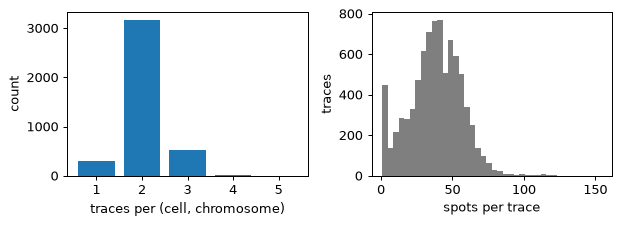

In [7]:
sp = cd.spots
per_cell_chrom = sp.groupby(["cell_id", "chrom"], observed=True)["trace_id"].nunique()
spots_per_trace = sp.groupby("trace_id", observed=True).size()
print("traces per (cell, chromosome):", per_cell_chrom.value_counts().sort_index().to_dict())
print(f"two traces in {np.mean(per_cell_chrom == 2):.0%} of the {len(per_cell_chrom):,} "
      f"(cell, chromosome) pairs; median {spots_per_trace.median():.0f} spots per trace (of 60 loci)")

fig, axes = plt.subplots(1, 2, figsize=(7, 2.6))
vc = per_cell_chrom.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color="tab:blue")
axes[0].set_xlabel("traces per (cell, chromosome)"); axes[0].set_ylabel("count")
axes[1].hist(spots_per_trace, bins=40, color="tab:gray")
axes[1].set_xlabel("spots per trace"); axes[1].set_ylabel("traces")
plt.tight_layout(); plt.show()

In [8]:
cell = cd.get_cell("0_1")
print(cell, "\n")
trace = cd.get_trace("0_1_1_0")          # cell 0_1, chr1, allele 0
print(f"trace 0_1_1_0: {trace.n_spots} spots on {trace.spots['chrom'].unique().tolist()} "
      f"(the subset keeps the full locus axis: {trace.n_bins} bins); first rows of to_dataframe():")
trace.to_dataframe().head()

ChromData: n_spots=1473, n_traces=39, n_cells=1, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly'] 

trace 0_1_1_0: 35 spots on ['chr1'] (the subset keeps the full locus axis: 1200 bins); first rows of to_dataframe():


,chrom,start,end,x,y,z,trace_id,spot_id,cell_id,extra_cell_roi_id
0,chr1,135625000,135650000,176.998,15.132,2.821,0_1_1_0,705144,0_1,0
1,chr1,135650000,135675000,176.953,15.056,2.771,0_1_1_0,705145,0_1,0
2,chr1,135700000,135725000,176.965,15.131,2.591,0_1_1_0,705147,0_1,0
3,chr1,135825000,135850000,176.700,14.609,2.969,0_1_1_0,705151,0_1,0
4,chr1,135850000,135875000,176.699,14.581,3.057,0_1_1_0,705152,0_1,0


## 5. Companion tables: cells and RNA spots

The 4DN experiment also deposited a *cell* table (per-cell RNA copy numbers of 45 genes,
nuclear / cytoplasmic area, the FOV-local cell centroid, a QC flag `keep1`) and a
*nascent-RNA spot* table (intron seqFISH spots in the same micron frame).  Pass them to
`from_fofct`: the cell table becomes `cd.cells` (gene counts as `rna.<gene>`, areas renamed
to `nucleus_area_um2` / `cytoplasm_area_um2`) and the RNA spots `cd.points['rna']`.
(Both companion files label their namespace `4dn_FOF-CT_quality` in the header; the loader
records what it read in `uns['fofct_companions']`.)

In [9]:
cd = ChromData.from_fofct(CORE, cell_table=CELLS, rna_table=RNA)
gene_cols = [c for c in cd.cells.columns if c.startswith("rna.")]
print(f"cells: {cd.cells.shape[0]} rows, {len(gene_cols)} rna.<gene> columns; "
      f"keep1 = 1 for {int(cd.cells['keep1'].sum())} cells (0 = excluded by the authors: illumination bias)")
cd.cells[["extra_cell_roi_id", "keep1", "centroid_x", "centroid_y", "nucleus_area_um2",
          "rna.Nanog", "rna.Sox2", "rna.Pou5f1"]].head()

cells: 201 rows, 45 rna.<gene> columns; keep1 = 1 for 151 cells (0 = excluded by the authors: illumination bias)


,extra_cell_roi_id,keep1,centroid_x,centroid_y,nucleus_area_um2,rna.Nanog,rna.Sox2,rna.Pou5f1
cell_id,,,,,,,,
0_1,0,0,170.079,18.531,242.161034,0.0,2.0,1.0
0_2,0,0,155.510,26.151,158.668204,1.0,6.0,14.0
0_3,0,0,25.481,34.890,203.735236,0.0,5.0,12.0
0_4,0,0,142.319,43.330,185.360448,24.0,82.0,140.0
0_5,0,0,100.033,58.749,151.485911,199.0,191.0,219.0


In [10]:
rna = cd.points["rna"]
print(f"{len(rna):,} RNA spots of {rna['gene'].nunique()} genes in {rna['cell_id'].nunique()} cells")
print({k: v["source"] for k, v in cd.uns["fofct_companions"].items()})
rna.head()

3,335 RNA spots of 23 genes in 201 cells
{'cells': '4DNFIFINA2U9.csv', 'rna': '4DNFIJ52NVDV.csv'}


,x,y,z,gene,gene_id,cell_id,spot_id,extra_cell_roi_id,peak_intensity
0,169.853,26.619,3.386,Auts2,NM_001363480,0_1,1022139,0,1142
1,152.599,24.696,2.371,Auts2,NM_001363480,0_2,1022140,0,1234
2,32.609,78.165,3.294,Auts2,NM_001363480,0_10,1022141,0,1732
3,32.891,77.844,3.247,Auts2,NM_001363480,0_10,1022142,0,2156
4,55.301,85.843,2.977,Auts2,NM_001363480,0_13,1022143,0,1260


## 6. Cell positions

Cell centroids are `cells` columns described by a record in `uns['cell_spatial']`;
`cd.cell_positions()` returns them as a table with the record in `.attrs`.  The loader knows
the unit and that the positions were measured, but not the frame.  We can check it from the
data: if the centroids share the frame of `coords`, each cell's DNA spots sit around its
centroid.

In [11]:
pos = cd.cell_positions()
print(pos.attrs["cell_spatial"])
spot_xy = pd.DataFrame(cd.coords[:, :2], columns=["x", "y"]).groupby(cd.spots["cell_id"].astype(str).values).median()
offset = np.hypot(spot_xy["x"] - pos.loc[spot_xy.index, "x"], spot_xy["y"] - pos.loc[spot_xy.index, "y"])
print(f"median DNA-spot position vs cell centroid: median offset {offset.median():.2f} um "
      f"(max {offset.max():.2f} um, nuclei are ~15 um across)")
print("cells per FOV (extra_cell_roi_id):", cd.cells["extra_cell_roi_id"].value_counts().sort_index().to_dict())

{'x_col': 'centroid_x', 'y_col': 'centroid_y', 'ndim': 2, 'status': 'measured', 'unit': 'micron', 'source': 'FOF-CT cell table Cent_ROI_x / Cent_ROI_y [/ Cent_ROI_z]'}
median DNA-spot position vs cell centroid: median offset 0.71 um (max 3.17 um, nuclei are ~15 um across)
cells per FOV (extra_cell_roi_id): {0: 46, 1: 37, 2: 46, 3: 41, 4: 31}


The offsets are below a micron, so the centroids are in the frame of `coords` — a
frame local to each of the 5 fields of view (`extra_cell_roi_id`), not one stitched tissue
frame.  Record that with `set_cell_positions` (registering the existing columns), so that
downstream tools (and the web browser) know how to use them.

In [12]:
cd.set_cell_positions(columns=["centroid_x", "centroid_y"], unit="micron", frame="fov",
                      region_col="extra_cell_roi_id", in_coords_frame=True, status="measured",
                      source="FOF-CT cell table 4DNFIFINA2U9 (Cent_ROI_x / Cent_ROI_y)")
pos = cd.cell_positions()
print(pos.attrs["cell_spatial"])
pos.head()

{'x_col': 'centroid_x', 'y_col': 'centroid_y', 'ndim': 2, 'unit': 'micron', 'frame': 'fov', 'region_col': 'extra_cell_roi_id', 'in_coords_frame': True, 'status': 'measured', 'source': 'FOF-CT cell table 4DNFIFINA2U9 (Cent_ROI_x / Cent_ROI_y)'}


,x,y,region
cell_id,,,
0_1,170.079,18.531,0
0_2,155.510,26.151,0
0_3,25.481,34.890,0
0_4,142.319,43.330,0
0_5,100.033,58.749,0


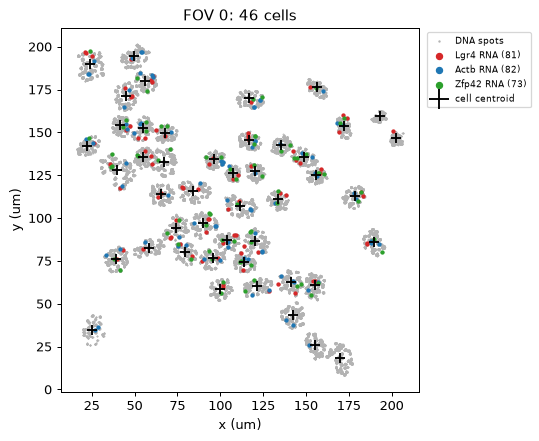

In [13]:
# one field of view: DNA spots, nascent-RNA spots and cell centroids share one micron frame
fov = 0
cells_fov = cd.cells.index[cd.cells["extra_cell_roi_id"] == fov]
on_fov = cd.spots["cell_id"].astype(str).isin(cells_fov).to_numpy()
rna_fov = rna[rna["cell_id"].astype(str).isin(cells_fov)]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cd.coords[on_fov, 0], cd.coords[on_fov, 1], s=0.2, c="0.7", rasterized=True, label="DNA spots")
for gene, colour in [("Lgr4", "tab:red"), ("Actb", "tab:blue"), ("Zfp42", "tab:green")]:
    g = rna_fov[rna_fov["gene"] == gene]
    ax.scatter(g["x"], g["y"], s=6, color=colour, label=f"{gene} RNA ({len(g)})")
p = pos.loc[cells_fov]
ax.scatter(p["x"], p["y"], marker="+", s=60, c="k", label="cell centroid")
ax.set_aspect("equal"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
ax.set_title(f"FOV {fov}: {len(cells_fov)} cells")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1), markerscale=2)
plt.tight_layout(); plt.show()

## 7. Write FOF-CT back with `to_fofct` and check the round trip

`to_fofct` writes the core table (header from `uns['fofct_header']`) and, on request, the cell
and RNA-spot tables; `uchrom.io.write_fofct(cd, path, ...)` is the same as a function.  Reading
the written files again must give the same object: coordinates, ids, loci, extra columns and
their dtypes, cells, RNA spots and headers.

In [14]:
written = cd.to_fofct(OUT / "takei2021_core.csv", cell_table=OUT / "takei2021_cells.csv",
                      rna_table=OUT / "takei2021_rna.csv")
for k, p in written.items():
    print(f"{k:5s} -> {Path(p)}  ({Path(p).stat().st_size / 1e6:.2f} MB)")

back = ChromData.from_fofct(written["core"], cell_table=written["cells"], rna_table=written["rna"])
pd.testing.assert_frame_equal(cd.to_dataframe(), back.to_dataframe(), check_exact=True)
pd.testing.assert_frame_equal(cd.cells, back.cells, check_exact=True)
pd.testing.assert_frame_equal(cd.points["rna"], back.points["rna"], check_exact=True)
assert cd.uns["fofct_header"] == back.uns["fofct_header"]
print(f"round trip identical: {back.n_spots:,} spots (coords, ids, loci, dtypes), "
      f"{back.cells.shape} cells table, {len(back.points['rna']):,} RNA spots, headers")

core  -> _out/takei2021_core.csv  (21.54 MB)
cells -> _out/takei2021_cells.csv  (0.06 MB)
rna   -> _out/takei2021_rna.csv  (0.21 MB)


round trip identical: 316,995 spots (coords, ids, loci, dtypes), (201, 51) cells table, 3,335 RNA spots, headers


What FOF-CT cannot hold is not written: `cellm`, `binm`, `layers`, `intervals`, `results`
and `uns` keys other than the header.  The cell-position record above is one of them
(`back.uns['cell_spatial']` is again the loader's default), so keep the full object in a
`.chromdata.zarr` store.

## 8. Store as `.chromdata.zarr`, or stream the import

For a large core table, `from_fofct(..., out=...)` reads the CSV in chunks and writes them
straight into a `.chromdata.zarr` store, so memory stays bounded by one chunk (plus the
writer's merge buffers, see `chromdata.settings.memory_budget`) instead of the whole table.
It returns the store opened **backed**: small tables are loaded, spots and coordinates are
read on access.  The streamed store holds the same data as writing the in-memory object.

In [15]:
import time

cd.write(OUT / "takei2021_mem.chromdata.zarr")       # the in-memory object, written in one go

t0 = time.perf_counter()
st = ChromData.from_fofct(CORE, cell_table=CELLS, rna_table=RNA,
                          out=OUT / "takei2021_stream.chromdata.zarr", chunksize=50_000)
print(f"streamed in {time.perf_counter() - t0:.1f} s (chunks of 50,000 rows) -> {type(st).__name__}")
print(st)

streamed in 1.6 s (chunks of 50,000 rows) -> BackedChromData
ChromData (backed: takei2021_stream.chromdata.zarr): n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  cells:   ['extra_cell_roi_id', 'keep1', 'centroid_x', 'centroid_y', 'nucleus_area_um2', 'cytoplasm_area_um2', 'rna.Eef2', 'rna.Auts2', 'rna.Bdnf', 'rna.Clu', 'rna.Cx3cr1', 'rna.Efna5', 'rna.Npy', 'rna.S100b', 'rna.Slc17a7', 'rna.Stmn2', 'rna.Zfp42', 'rna.Myc', 'rna.Ccnd2', 'rna.Mcm2', 'rna.Mki67', 'rna.Sox2', 'rna.Nes', 'rna.Cdk1', 'rna.Mtf2', 'rna.Jade1', 'rna.Cenpa', 'rna.Aurka', 'rna.Plk1', 'rna.Mdm2', 'rna.Aebp2', 'rna.Tet1', 'rna.Nodal', 'rna.Tfcp2l1', 'rna.Tdh', 'rna.Sall4', 'rna.Nanog', 'rna.Esrrb', 'rna.Pou5f1', 'rna.Klf6', 'rna.Ctgf', 'rna.Peg10', 'rna.Myh9', 'rna.Tbx3', 'rna.Otx2', 'rna.Dnmt3a', 'rna.Dnmt3b', 'rna.Lin28a', 'rna.Lin28b', 'rna.Zscan4c', 'rna.Zfp352'] (201 cells)
  points:  {'rna': 3335}
  uns

In [16]:
# backed access reads only what is asked for
one = st.get_cell("0_1")
print(f"get_cell('0_1'): {one.n_spots} spots, {one.n_traces} traces")

# the streamed store equals the in-memory import (rows are stored sorted: compare by spot_id)
mem = ChromData.read(OUT / "takei2021_mem.chromdata.zarr")
a = mem.to_dataframe().sort_values("spot_id").reset_index(drop=True)
b = st.to_memory().to_dataframe().sort_values("spot_id").reset_index(drop=True)
pd.testing.assert_frame_equal(a, b, check_exact=True)
pd.testing.assert_frame_equal(mem.cells, st.cells, check_exact=True)
print(f"streamed store == in-memory import: {len(b):,} spots, {len(st.cells)} cells, "
      f"{len(st.points['rna']):,} RNA spots")

get_cell('0_1'): 1473 spots, 39 traces


streamed store == in-memory import: 316,995 spots, 201 cells, 3,335 RNA spots


## Next steps

- `chromdata_basics.ipynb` — the `ChromData` container in depth (bins, tracks, results, backed stores).
- The same Takei 2021 table drives the structure tutorials: `loop_calling.ipynb`,
  `tad_calling.ipynb`, `compartment.ipynb`, `fishnet_domains.ipynb`.
- `jie_aligner.ipynb` starts one step earlier, from the raw seqFISH+ spots of the same
  experiment, and assigns them to traces.
- Other imaging importers: `import_pyhim_ecsv.ipynb` (PyHiM ECSV traces),
  `import_seqfish_multiomics.ipynb` (Takei 2025 seqFISH+ multi-omics with per-spot IF tracks).
- Look at the store interactively: `python -m uchrom_browser tutorials/_out/takei2021_stream.chromdata.zarr`.